In [1]:
# maine 6 bus
import numpy as np
import pandas as pd
import pypsa
from scipy.signal import lfilter
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [3]:
# 1. Historical loads; resolve the repeated November hour, then use UTC snapshots.
df = pd.read_csv("../data/maine_selected_6_nodes_202501_202609.csv")
local = pd.to_datetime(df.Date) + pd.to_timedelta(df.Hour_Ending - 1, unit="h")
utc = (local.dt.tz_localize("America/New_York", ambiguous=df.Hour_Occurrence.eq(1).to_numpy())
       .dt.tz_convert("UTC").dt.tz_localize(None))
load = df.filter(like="_MW_Factor").copy()
load.columns = ["Spring", "Topsham", "Gulf", "Raymond", "Trenton", "Chester"]
load.index = pd.DatetimeIndex(utc)
load = load.dropna().sort_index()   # No imputation of missing nodal weights


In [4]:
# 2. Size installed capacity using 2025 only (avoid calibration on 2026 test data).
train = load.loc[load.index < pd.Timestamp("2026-01-01 05:00")]
N = train[["Chester", "Trenton", "Gulf"]].sum(axis=1).quantile(0.95)
S = train[["Spring", "Topsham", "Raymond"]].sum(axis=1).quantile(0.95)
up5 = lambda x: float(5 * np.ceil(x / 5))
gens = {  # name: (bus, installed MW, marginal $/MWh)
    "wind":    ("Chester", up5(.80*N), 0),
    "hydro":   ("Gulf",    up5(.65*N), 12),
    "thermal": ("Trenton", up5(1.15*N), 28),
    "ccgt":    ("Spring",  up5(1.00*S), 65),
    "peaker":  ("Topsham", up5(.60*S), 100),
    "backup":  ("Raymond", up5(.45*S), 180),
}

In [5]:
# 3. Build an intentionally synthetic, meshed 115-kV network.
n = pypsa.Network()
n.set_snapshots(load.index)
for bus in load:
    n.add("Bus", bus, v_nom=115)
    n.add("Load", f"load_{bus}", bus=bus, p_set=load[bus])
for name, (bus, mw, cost) in gens.items():
    n.add("Generator", name, bus=bus, p_nom=mw, marginal_cost=cost)


/Users/davidreynolds/Documents/pers/gridlearn2/.venv/lib/python3.14/site-packages/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)


In [8]:
# Correlated synthetic wind availability, pending observed wind profiles.
noise = np.random.default_rng(7).normal(size=len(load))
wind_cf = np.clip(.43 + .22*lfilter([np.sqrt(1-.95**2)], [1, -.95], noise), .03, .95)
n.generators_t.p_max_pu["wind"] = wind_cf

# Lines: bus0, bus1, reactance in ohms, thermal rating in MVA.
lines = [
    ("Chester", "Trenton", 13, up5(.70*gens["wind"][1])),
    ("Chester", "Gulf",    18, up5(.55*gens["wind"][1])),
    ("Trenton", "Gulf",     9, up5(1.20*N)),
    ("Trenton", "Topsham", 15, 60), # northern/southern tie
    ("Gulf", "Spring",    18, 48), # second tie
    ("Spring", "Topsham",  9, up5(.60*S)),
    ("Spring", "Raymond", 12, up5(.13*S)), # local bottleneck
    ("Topsham", "Raymond",14, up5(.13*S)),
]
for a, b, x, rating in lines:
    n.add("Line", f"{a}-{b}", bus0=a, bus1=b, x=x, r=0, s_nom=rating)


In [9]:
# 4. Smoke test: one January week and one July week, then save network.
hours = n.snapshots #[(n.snapshots.year == 2025) &
                    # (n.snapshots.month.isin([1, 7])) & (n.snapshots.day <= 7)]
status, condition = n.optimize(snapshots=hours, assign_all_duals=True, solver_name="highs")
print("Optimization:", status, condition)
print("Generator MW:\n", n.generators[["bus", "p_nom", "marginal_cost"]])
print("Line ratings (MVA):\n", n.lines["s_nom"])
if status == "ok":
    spread = n.buses_t.marginal_price.loc[hours, "Topsham"] - n.buses_t.marginal_price.loc[hours, "Chester"]
    binding = n.lines_t.p0.loc[hours].abs().ge(n.lines.s_nom - 1e-3).any(axis=1)
    print(f"Mean Topsham–Chester LMP spread: ${spread.mean():.1f}/MWh")
    print(f"Hours with at least one binding line: {binding.mean():.1%}")
n.export_to_netcdf("maine_six_bus.nc")

<positron-console-cell-9>:4: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
Index(['Spring', 'Topsham', 'Gulf', 'Raymond', 'Trenton', 'Chester'], dtype='object', name='name')
Index(['Chester-Trenton', 'Chester-Gulf', 'Trenton-Gulf', 'Trenton-Topsham',
       'Gulf-Spring', 'Spring-Topsham', 'Spring-Raymond', 'Topsham-Raymond'],
      dtype='object', name='name')
Index(['Chester-Trenton', 'Chester-Gulf', 'Trenton-Gulf', 'Trenton-Topsham',
       'Gulf-Spring', 'Spring-Topsham', 'Spring-Raymond', 'Topsham-Raymond'],
      dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 2/2 [00:00<00:00, 123.37it/s]
INFO:linopy.io: Writing time: 0.36s


Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-fg7rrh3w has 556184 rows; 210448 cols; 901920 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+02]
  Cost    [1e+01, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+02]
Presolving model
135288 rows, 210448 cols, 481024 nonzeros 0s
Dependent equations search running on 119815 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.01s (limit = 1000.00s)
119815 rows, 194975 cols, 449784 nonzeros 0s
Presolve reductions: rows 119815(-436369); columns 194975(-15473); nonzeros 449784(-452136) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -3.4462341483e+00 Pr: 119807(3.43073e+07) 0.8s
     138352     6.2838253903e+07 Pr: 0(0) 3.6s

Performed postsolve
Solving the original LP from 

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 210448 primals, 556184 duals
Objective: 6.28e+07
Solver: highs
Runtime: 3.97s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Kirchhoff-Voltage-Law were not assigned to the network.



Model name          : linopy-problem-fg7rrh3w
Model status        : Optimal
Simplex   iterations: 138352
Objective value     :  6.2838253903e+07
P-D objective error :  1.1269849751e-13
HiGHS run time      :          3.97


INFO:pypsa.network.io:Exported network 'Unnamed Network' saved to 'maine_six_bus.nc contains: generators, lines, sub_networks, buses, loads


Optimization: ok optimal
Generator MW:
              bus  p_nom  marginal_cost
name                                  
wind     Chester   55.0            0.0
hydro       Gulf   45.0           12.0
thermal  Trenton   80.0           28.0
ccgt      Spring  150.0           65.0
peaker   Topsham   90.0          100.0
backup   Raymond   70.0          180.0
Line ratings (MVA):
 name
Chester-Trenton    40.0
Chester-Gulf       35.0
Trenton-Gulf       85.0
Trenton-Topsham    60.0
Gulf-Spring        48.0
Spring-Topsham     90.0
Spring-Raymond     20.0
Topsham-Raymond    20.0
Name: s_nom, dtype: float64
Mean Topsham–Chester LMP spread: $5.0/MWh
Hours with at least one binding line: 17.5%


<xarray.Dataset> Size: 9MB
Dimensions:                   (snapshots: 15032, generators_i: 6,
                               generators_t_p_max_pu_i: 1, generators_t_p_i: 6,
                               generators_t_mu_upper_i: 6,
                               generators_t_mu_lower_i: 6, lines_i: 8,
                               lines_t_p0_i: 8, lines_t_p1_i: 8,
                               lines_t_mu_upper_i: 4, sub_networks_i: 1,
                               buses_i: 6, buses_t_p_i: 6, buses_t_v_ang_i: 6,
                               buses_t_marginal_price_i: 6, loads_i: 6,
                               loads_t_p_set_i: 6, loads_t_p_i: 6)
Coordinates: (12/18)
  * snapshots                 (snapshots) int64 120kB 0 1 2 ... 15030 15031
  * generators_i              (generators_i) object 48B 'wind' ... 'backup'
  * generators_t_p_max_pu_i   (generators_t_p_max_pu_i) object 8B 'wind'
  * generators_t_p_i          (generators_t_p_i) object 48B 'wind' ... 'backup'
  * generators_t_mu_upper_i   (generators_t_mu_upper_i) object 48B 'wind' ......
  * generators_t_mu_lower_i   (generators_t_mu_lower_i) object 48B 'wind' ......
    ...                        ...
  * buses_t_p_i               (buses_t_p_i) object 48B 'Spring' ... 'Chester'
  * buses_t_v_ang_i           (buses_t_v_ang_i) object 48B 'Spring' ... 'Ches...
  * buses_t_marginal_price_i  (buses_t_marginal_price_i) object 48B 'Spring' ...
  * loads_i                   (loads_i) object 48B 'load_Spring' ... 'load_Ch...
  * loads_t_p_set_i           (loads_t_p_set_i) object 48B 'load_Spring' ... ...
  * loads_t_p_i               (loads_t_p_i) object 48B 'load_Spring' ... 'loa...
Data variables: (12/38)
    snapshots_snapshot        (snapshots) datetime64[us] 120kB 2025-01-01T05:...
    snapshots_objective       (snapshots) float64 120kB 1.0 1.0 1.0 ... 1.0 1.0
    snapshots_stores          (snapshots) float64 120kB 1.0 1.0 1.0 ... 1.0 1.0
    snapshots_generators      (snapshots) float64 120kB 1.0 1.0 1.0 ... 1.0 1.0
    generators_bus            (generators_i) object 48B 'Chester' ... 'Raymond'
    generators_control        (generators_i) object 48B 'Slack' 'PQ' ... 'PQ'
    ...                        ...
    buses_t_p                 (snapshots, buses_t_p_i) float64 722kB -28.65 ....
    buses_t_v_ang             (snapshots, buses_t_v_ang_i) float64 722kB -0.0...
    buses_t_marginal_price    (snapshots, buses_t_marginal_price_i) float64 722kB ...
    loads_bus                 (loads_i) object 48B 'Spring' ... 'Chester'
    loads_t_p_set             (snapshots, loads_t_p_set_i) float64 722kB 48.0...
    loads_t_p                 (snapshots, loads_t_p_i) float64 722kB 48.0 ......
Attributes:
    network__linearized_uc:       0
    network__multi_invest:        0
    network__objective:           62838253.90334407
    network__objective_constant:  0.0
    network_name:                 Unnamed Network
    network_pypsa_version:        1.4.0
    network_srid:                 4326
    crs:                          {"_crs": "GEOGCRS[\"WGS 84\",ENSEMBLE[\"Wor...
    meta:                         {}

In [ ]:
# Hourly line utilization (fraction of capacity)
flows = n.lines_t.p0.loc[hours]
limits = n.lines.s_nom * n.lines.s_max_pu

util = flows.abs().div(limits, axis=1)

# Identify hours when each line is at its limit
congested = util >= 0.999

# Summary by line
summary = pd.DataFrame({
    "pct_hours_at_limit": 100 * congested.mean(),
    "p95_utilization": 100 * util.quantile(0.95),
    "max_utilization": 100 * util.max()
})

print(summary.round(1))

# Overall frequency
print("Hours with at least one constrained line:",
      round(100 * congested.any(axis=1).mean(), 1), "%")

                 pct_hours_at_limit  p95_utilization  max_utilization
name                                                                 
Chester-Trenton                 0.0             44.3             84.1
Chester-Gulf                    0.0             45.5             64.3
Trenton-Gulf                    0.0             16.1             33.1
Trenton-Topsham                 3.2             98.7            100.0
Gulf-Spring                     9.7            100.0            100.0
Spring-Topsham                  0.0             14.6             24.4
Spring-Raymond                  4.8             99.2            100.0
Topsham-Raymond                 0.2             77.8            100.0
Hours with at least one constrained line: 17.7 %


In [27]:
lmp = n.buses_t.marginal_price.loc[hours]

spread = lmp.max(axis=1) - lmp.min(axis=1)

print(spread.describe(percentiles=[.5, .9, .95, .99]))

print("Hours with spread > $1:",
      round(100 * (spread > 1).mean(), 1), "%")

print("Mean spread when > $1:",
      round(spread[spread > 1].mean(), 2))

count    15032.000000
mean        11.039441
std         26.014428
min          0.000000
50%          0.000000
90%         48.900692
95%         48.900692
99%        101.702105
max        115.000000
dtype: float64
Hours with spread > $1: 17.5 %
Mean spread when > $1: 63.19


In [26]:
monthly = (
    (spread > 1)
    .groupby(spread.index.to_period("M"))
    .mean() * 100
)

print(monthly.round(1))

snapshot
2025-01    23.0
2025-02    26.2
2025-03    17.1
2025-04     6.0
2025-05    14.6
2025-06    19.5
2025-07    26.3
2025-08    24.3
2025-09    12.8
2025-10     2.2
2025-11     4.0
2025-12    23.5
2026-01    24.5
2026-02    38.2
2026-03     6.7
2026-04     1.7
2026-05     4.2
2026-06    18.7
2026-07    26.6
2026-08    33.2
2026-09    13.5
2026-10     0.0
Freq: M, dtype: float64


In [25]:
dispatch = n.generators_t.p.loc[hours]

print("Mean dispatch (MW):")
print(dispatch.mean().round(1))

print("\nPercent of hours generating:")
print((100 * (dispatch > 0.01).mean()).round(1))

print("\nMaximum dispatch (MW):")
print(dispatch.max().round(1))

Mean dispatch (MW):
name
wind       23.2
hydro      45.0
thermal    74.1
ccgt       23.1
peaker      0.6
backup      0.0
dtype: float64

Percent of hours generating:
name
wind       100.0
hydro      100.0
thermal    100.0
ccgt        75.8
peaker       4.8
backup       0.1
dtype: float64

Maximum dispatch (MW):
name
wind       52.2
hydro      45.0
thermal    80.0
ccgt       93.8
peaker     49.3
backup     60.0
dtype: float64


In [61]:
#lmp.head()

lmp_response = lmp.assign(y = lambda x: x["Spring"] - x["Chester"])["y"]

# Shadow prices for hitting the upper flow limit (e.g., forward flow congestion)
#mu_upper = n.lines_t.mu_upper

# Shadow prices for hitting the lower flow limit (e.g., reverse flow congestion)
#mu_lower = n.lines_t.mu_lower

#lmp.plot()

#load.head()

# Conceptually similar to R's inner_join, but keyed directly on the index
#df_merged = lmp_response.join(load, how='inner')
load["y"] = lmp_response

load.head()



,Spring,Topsham,Gulf,Raymond,Trenton,Chester,y,res
2025-01-01 05:00:00,48.0,47.0,26.0,18.0,15.0,14.0,0.0,-2.799734
2025-01-01 06:00:00,48.0,44.0,26.0,19.0,14.0,13.0,0.0,-3.340671
2025-01-01 07:00:00,46.0,43.0,26.0,18.0,14.0,14.0,0.0,-2.111929
2025-01-01 08:00:00,43.0,42.0,26.0,18.0,13.0,13.0,0.0,-2.287181
2025-01-01 09:00:00,45.0,41.0,26.0,19.0,13.0,14.0,0.0,-2.015925


In [53]:
model = smf.ols("y ~ Spring + Topsham + Gulf + Raymond + Trenton + Chester", data=load).fit()

# Print the full traditional diagnostic summary 
# (Coefficients, standard errors, t-stats, p-values, R-squared)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.088
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     241.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          9.49e-296
Time:                        19:58:20   Log-Likelihood:                -60573.
No. Observations:               15032   AIC:                         1.212e+05
Df Residuals:                   15025   BIC:                         1.212e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     15.0308      0.740     20.308      0.0

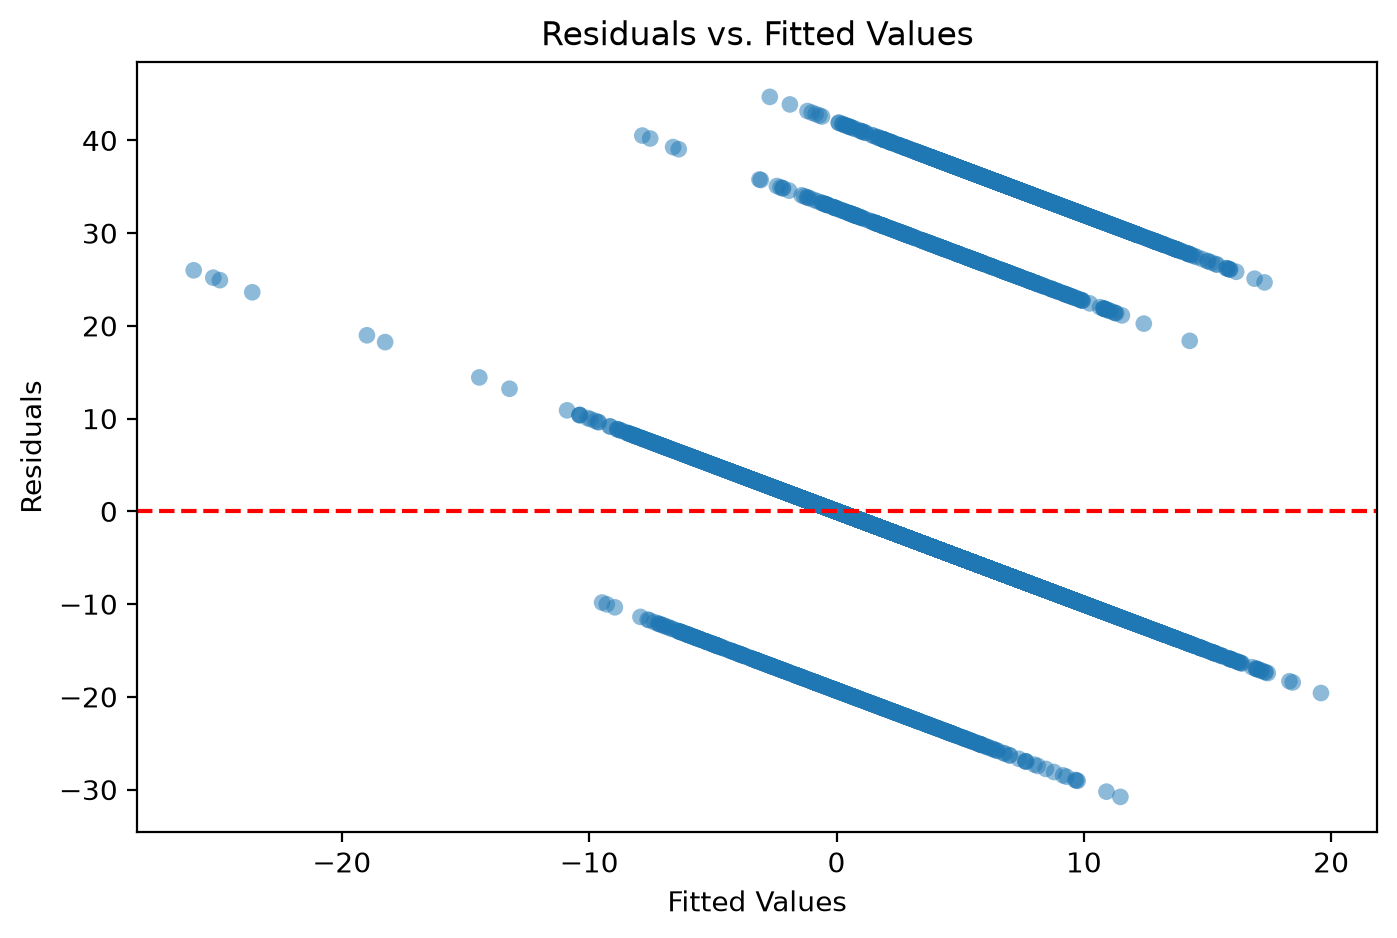

In [62]:
# Extract the calculated arrays from the model object
fitted_vals = model.fittedvalues
residuals = model.resid

# Create a scatter plot of Residuals vs. Fitted values
plt.figure(figsize=(8, 5))
plt.scatter(fitted_vals, residuals, alpha=0.5, edgecolor='none')

# Add a reference line at zero
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)

plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values')
plt.show()

<Axes: >

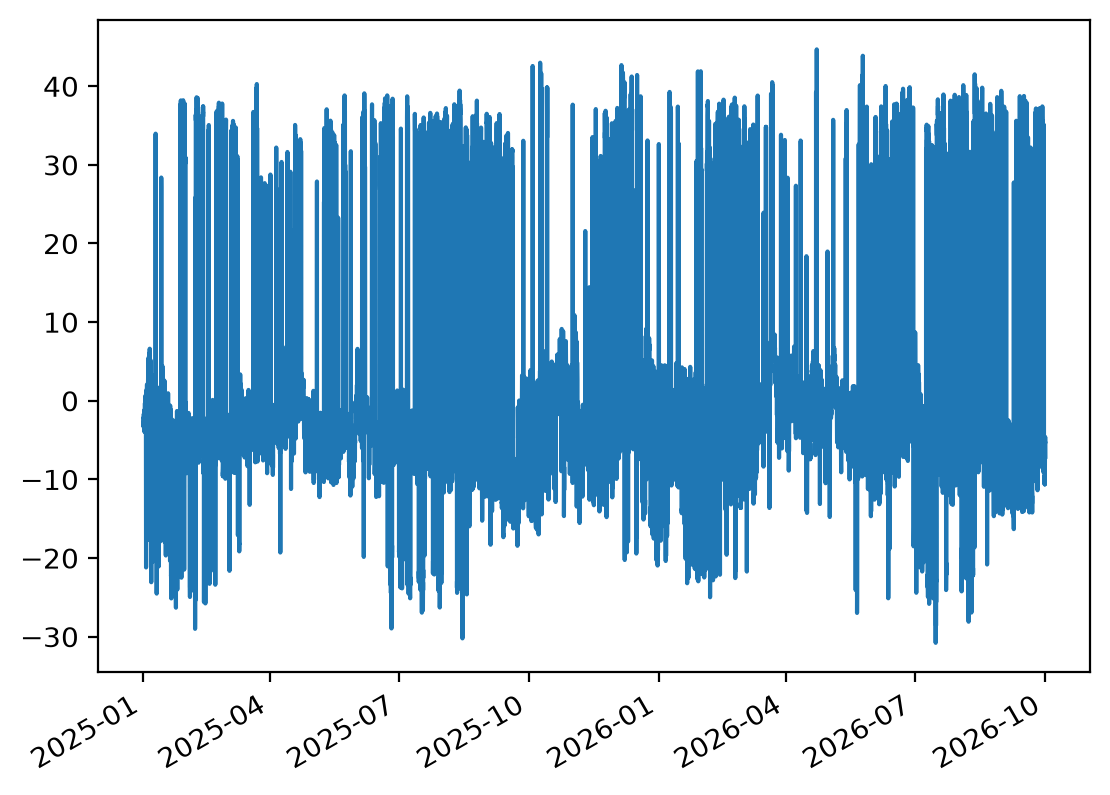

In [60]:
load["res"] = residuals

load["res"].plot()